# 07 · Geospatial Analysis & Visualization
*EV capacity planning for PowerCharge Utilities · notebook 7 of 8 · Anna Tafri*

Reads: `data/processed/*.csv`, `reports/upgrade_plan.csv`, `data/external/north_america_countries.geojson` (Natural Earth, public domain)  
Writes: `data/processed/substations_geo.geojson`, `reports/figures/07_*.png`

### Business questions
1. Where are the bottlenecks and the planned upgrades on the map?
2. Are bottlenecks clustered geographically, which would point to a regional problem rather than isolated sites?
3. Does the station-to-substation mapping make physical sense? If not, how much would a corrected mapping change the plan?

> **Requirement:** this notebook uses GeoPandas. If `import geopandas` fails in your environment, install it with conda from the Anaconda Prompt: `conda install -c conda-forge geopandas`.


## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from shapely.geometry import LineString

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
EXTERNAL = PROJECT_ROOT / "data" / "external"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ev_utils import capacity_model

pd.set_option("display.float_format", "{:,.2f}".format)

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
LAND, BORDER = "#efeee9", "#c9c8c2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
TIER_COLORS = {"Tier 1 - Act": "#d03b3b", "Tier 2 - Plan": "#fab219", "Tier 3 - Monitor": "#2a78d6"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

print("geopandas", gpd.__version__)

geopandas 1.2.0


## 1. Build the GeoDataFrames
- **CRS choice.** Raw coordinates are WGS84 latitude/longitude (EPSG:4326). Degrees are not a unit of distance, so for distances, nearest-neighbour joins, and maps we project to North America Albers Equal Area (ESRI:102008), which keeps areas and distances realistic across the continent.
- Three layers: substations (with capacity, tier, and planned action), charging stations (with energy and charger type), and service connections (a line from each station to its assigned substation).

In [2]:
CRS = "ESRI:102008"

events = pd.read_csv(PROCESSED / "ev_events_clean.csv", parse_dates=["timestamp"])
subs = pd.read_csv(PROCESSED / "substations_clean.csv")
scores = pd.read_csv(PROCESSED / "bottleneck_scores.csv", index_col="substation_id")
plan = pd.read_csv(REPORTS / "upgrade_plan.csv", index_col="substation_id")
countries = gpd.read_file(EXTERNAL / "north_america_countries.geojson").to_crs(CRS)

# Planned action per substation (robust plan from Notebook 06)
def action_type(r):
    if pd.isna(r["cost ($M)"]):
        return "No action needed"
    if r["uprates"] > 0 or r["new bay"] > 0:
        return "Wire (transformer uprate)"
    return "Non-wire (tariff / smart charging / battery)"
plan["action_type"] = plan.apply(action_type, axis=1)

sub_gdf = gpd.GeoDataFrame(
    subs.set_index("substation_id")
        .join(scores[["tier", "risk_score", "breach_prob", "ev_peak_mw", "breaking_multiple"]])
        .join(plan[["cost ($M)", "trigger_multiple", "phase", "action_type"]]),
    geometry=gpd.points_from_xy(subs["sub_lon"], subs["sub_lat"]), crs="EPSG:4326").to_crs(CRS)
sub_gdf["action_type"] = sub_gdf["action_type"].fillna("No action needed")

st_gdf = gpd.GeoDataFrame(events, geometry=gpd.points_from_xy(events["station_lon"], events["station_lat"]),
                          crs="EPSG:4326").to_crs(CRS)

links = gpd.GeoDataFrame(
    st_gdf[["substation_id", "electricity_consumption_kwh"]],
    geometry=[LineString([p, sub_gdf.geometry[s]]) for p, s in zip(st_gdf.geometry, st_gdf["substation_id"])],
    crs=CRS)
links["length_km"] = links.length / 1000

print(f"{len(sub_gdf)} substations | {len(st_gdf)} charging stations | {len(links)} service connections")

50 substations | 97 charging stations | 97 service connections


## 2. Where is everything? Spatial join with country boundaries

In [3]:
loc = pd.concat({
    "substations": gpd.sjoin(sub_gdf, countries, how="left")["country"].fillna("Outside land"),
    "charging stations": gpd.sjoin(st_gdf, countries, how="left")["country"].fillna("Outside land"),
}, names=["layer"]).groupby(level=0).value_counts().unstack(fill_value=0)
loc

country,Canada,Mexico,United States of America
layer,,,
charging stations,55,6,36
substations,31,4,15


**Reading it:** every asset falls on land, mostly in Canada, then the US and Mexico. This is a useful sanity check. The synthetic coordinates are at least physically placed. As Notebook 01 noted, though, the footprint covers a whole continent, so the maps show relative patterns, not a real service territory.

## 3. Network map: substations by bottleneck tier

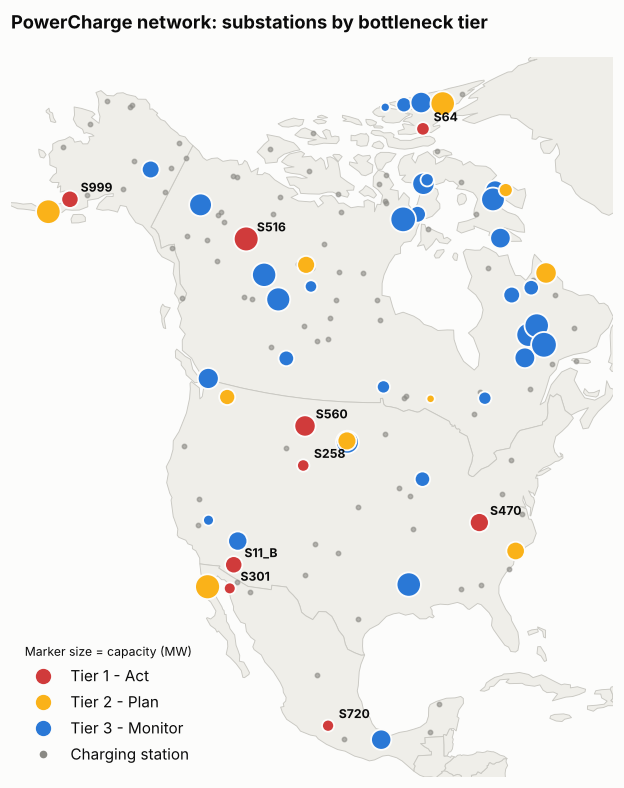

In [4]:
def basemap(ax):
    countries.plot(ax=ax, color=LAND, edgecolor=BORDER, linewidth=0.6)
    xmin, ymin, xmax, ymax = pd.concat([sub_gdf.geometry, st_gdf.geometry]).total_bounds
    pad = 400_000
    ax.set_xlim(xmin - pad, xmax + pad); ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(11, 8.5))
basemap(ax)
st_gdf.plot(ax=ax, color=MUTED, markersize=8, alpha=0.6, zorder=2)
for tier in ["Tier 3 - Monitor", "Tier 2 - Plan", "Tier 1 - Act"]:
    t = sub_gdf[sub_gdf["tier"] == tier]
    t.plot(ax=ax, color=TIER_COLORS[tier], markersize=t["capacity_mw"] * 3, edgecolor=SURFACE, linewidth=1.2, zorder=3)
for sid, r in sub_gdf[sub_gdf["tier"] == "Tier 1 - Act"].iterrows():
    ax.annotate(sid.replace("Substation_", "S"), (r.geometry.x, r.geometry.y), xytext=(7, 5),
                textcoords="offset points", fontsize=8, color=INK, fontweight="bold")
handles = [Line2D([], [], marker="o", linestyle="", markersize=9, color=c, label=l) for l, c in TIER_COLORS.items()]
handles += [Line2D([], [], marker="o", linestyle="", markersize=4, color=MUTED, label="Charging station")]
ax.legend(handles=handles, loc="lower left", title="Marker size = capacity (MW)", title_fontsize=8)
ax.set_title("PowerCharge network: substations by bottleneck tier")
save(fig, "07_01_network_tiers"); plt.show()

## 4. Are the bottlenecks clustered?
If Tier 1–2 substations sit close together, the cause could be regional (for example a fast-growing metro area). If they are scattered, the causes are local. We test this with a permutation test: compare the average nearest-neighbour distance among at-risk substations against 5,000 random sets of substations of the same size.

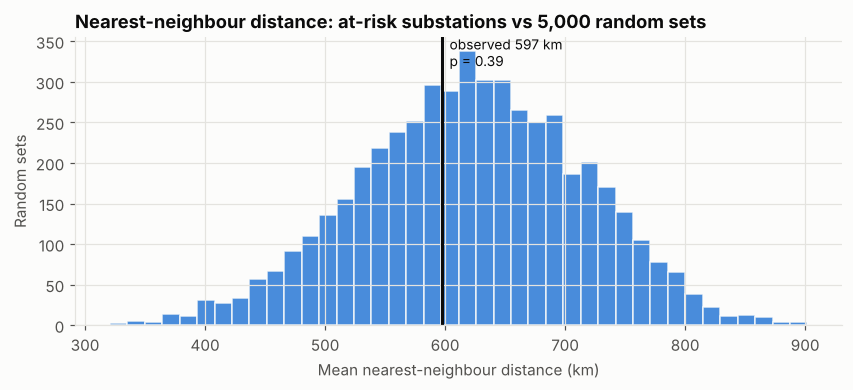

At-risk substations: 19 | observed 597 km | random median 622 km | p = 0.39


In [5]:
def mean_nn_km(points):
    xy = np.column_stack([points.x, points.y])
    d = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(d, np.inf)
    return d.min(axis=1).mean() / 1000

at_risk = sub_gdf["tier"].isin(["Tier 1 - Act", "Tier 2 - Plan"])
observed = mean_nn_km(sub_gdf.geometry[at_risk])

rng = np.random.default_rng(42)
null = np.array([mean_nn_km(sub_gdf.geometry.iloc[rng.choice(len(sub_gdf), at_risk.sum(), replace=False)])
                 for _ in range(5000)])
p_value = (null <= observed).mean()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(null, bins=40, color=SERIES[0], alpha=0.85, edgecolor=SURFACE)
ax.axvline(observed, color=INK, linewidth=2)
ax.text(observed, ax.get_ylim()[1] * 0.9, f"  observed {observed:,.0f} km\n  p = {p_value:.2f}", fontsize=9, color=INK)
ax.set(title="Nearest-neighbour distance: at-risk substations vs 5,000 random sets",
       xlabel="Mean nearest-neighbour distance (km)", ylabel="Random sets")
save(fig, "07_02_clustering_test"); plt.show()
print(f"At-risk substations: {at_risk.sum()} | observed {observed:,.0f} km | random median {np.median(null):,.0f} km | p = {p_value:.2f}")

**Reading it:** the at-risk substations sit ~600 km from their nearest at-risk neighbour on average, about the same as randomly chosen sets (median ~620 km). With p ≈ 0.39 there is no evidence of clustering. The bottlenecks are local, site-specific problems, not a regional one. That supports a substation-by-substation programme like Notebook 06 rather than one large regional build.

## 5. Do the service connections make physical sense?
In a real distribution network, a charging station is fed by a nearby substation, typically within a few tens of km. Below, each line connects a station to the substation the data says serves it.

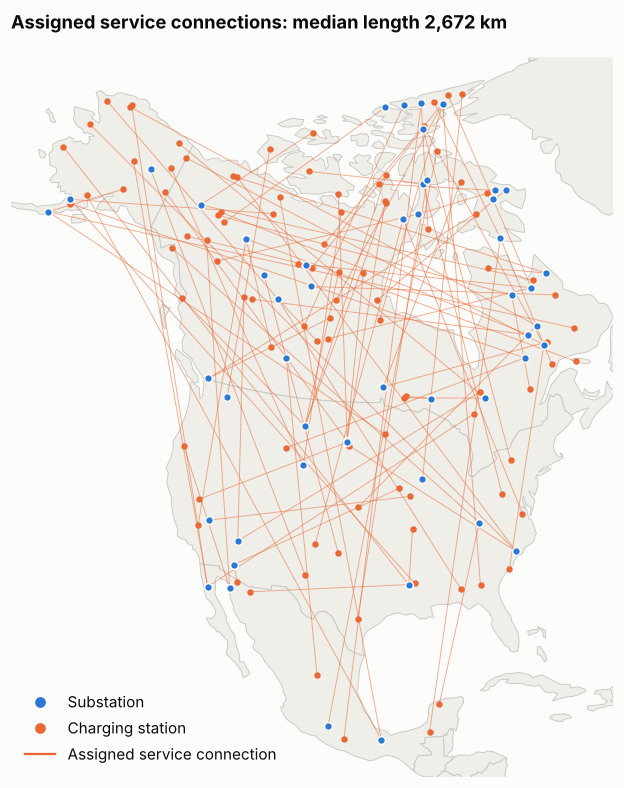

In [6]:
fig, ax = plt.subplots(figsize=(11, 8.5))
basemap(ax)
links.plot(ax=ax, color=SERIES[1], linewidth=0.6, alpha=0.55, zorder=2)
st_gdf.plot(ax=ax, color=SERIES[1], markersize=10, zorder=3)
sub_gdf.plot(ax=ax, color=SERIES[0], markersize=26, edgecolor=SURFACE, linewidth=1, zorder=4)
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color=SERIES[0], label="Substation"),
                   Line2D([], [], marker="o", linestyle="", color=SERIES[1], label="Charging station"),
                   Line2D([], [], color=SERIES[1], label="Assigned service connection")], loc="lower left")
ax.set_title(f"Assigned service connections: median length {links['length_km'].median():,.0f} km")
save(fig, "07_03_service_connections"); plt.show()

In [7]:
nearest = gpd.sjoin_nearest(st_gdf[["substation_id", "geometry"]].rename(columns={"substation_id": "assigned_sub"}),
                            sub_gdf[["geometry"]].reset_index(), distance_col="nearest_m")
nearest = nearest[~nearest.index.duplicated()]   # ties: keep the first nearest
check = pd.Series({
    "Stations assigned to their nearest substation": (nearest["assigned_sub"] == nearest["substation_id"]).mean(),
    "Median assigned distance (km)": links["length_km"].median(),
    "Median distance to nearest substation (km)": nearest["nearest_m"].median() / 1000,
})
check.to_frame("value")

,value
Stations assigned to their nearest substation,0.00
Median assigned distance (km),"2,672.21"
Median distance to nearest substation (km),364.80


**Reading it: a significant data-quality finding**
- None of the 97 stations is assigned to its nearest substation. The median assigned connection is about 2,700 km long, compared with about 365 km to the nearest substation.
- No distribution feeder is thousands of km long. So either `Substation_ID` in the EV data is a logical or billing reference rather than the electrical connection, or the coordinates were generated independently of the IDs.
- Why it matters: the whole capacity assessment allocates EV load through `Substation_ID`. If that link is wrong in real data, the bottleneck list would be wrong too. The next section measures how sensitive the results are to this.

## 6. What-if: re-assign every station to its nearest substation
We rerun the Notebook 04 capacity model with a geographic allocation (nearest substation) and compare the bottleneck lists.

In [8]:
CHARGER_KW = {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 50.0}
BASE = dict(charger_kw=CHARGER_KW, base_load_util=0.65, coincidence=0.7, planning_limit=0.80)

events_geo = events.copy()
events_geo["substation_id"] = nearest["substation_id"].reindex(events.index).values

as_given = capacity_model(events, subs, growth=20, **BASE)
geographic = capacity_model(events_geo, subs, growth=20, **BASE)

breach_given = set(as_given.index[as_given["utilisation"] >= 0.80])
breach_geo = set(geographic.index[geographic["utilisation"] >= 0.80])
pd.Series({
    "Breaching at 20x - ID-based allocation": len(breach_given),
    "Breaching at 20x - nearest-substation allocation": len(breach_geo),
    "In both lists": len(breach_given & breach_geo),
    "Substations receiving EV load (ID-based)": (as_given["ev_peak_mw"] > 0).sum(),
    "Substations receiving EV load (geographic)": (geographic["ev_peak_mw"] > 0).sum(),
}).to_frame("count")

,count
Breaching at 20x - ID-based allocation,9
Breaching at 20x - nearest-substation allocation,10
In both lists,3
Substations receiving EV load (ID-based),49
Substations receiving EV load (geographic),38


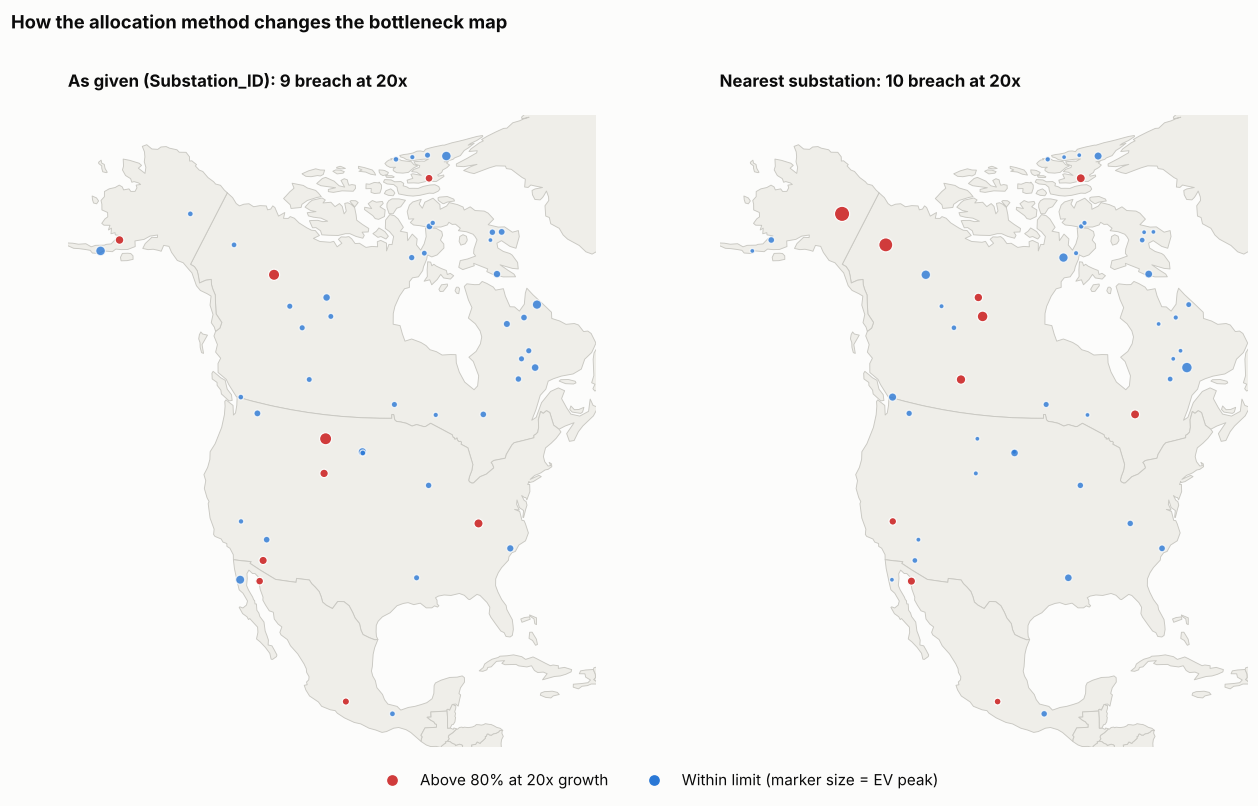

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2))
for ax, (title, res) in zip(axes, [("As given (Substation_ID)", as_given), ("Nearest substation", geographic)]):
    basemap(ax)
    g = sub_gdf[["geometry"]].join(res[["utilisation", "ev_peak_mw"]])
    ok, bad = g[g["utilisation"] < 0.8], g[g["utilisation"] >= 0.8]
    ok.plot(ax=ax, color=SERIES[0], markersize=10 + ok["ev_peak_mw"] * 60, edgecolor=SURFACE, linewidth=0.8, alpha=0.8)
    bad.plot(ax=ax, color="#d03b3b", markersize=10 + bad["ev_peak_mw"] * 60, edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(f"{title}: {len(bad)} breach at 20x", fontsize=11)
fig.legend(handles=[Line2D([], [], marker="o", linestyle="", color="#d03b3b", label="Above 80% at 20x growth"),
                    Line2D([], [], marker="o", linestyle="", color=SERIES[0], label="Within limit (marker size = EV peak)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("How the allocation method changes the bottleneck map", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.94)); save(fig, "07_04_allocation_whatif"); plt.show()

**Reading it**
- The number of breaching substations barely changes (9 vs 10), but only 3 substations appear on both lists. The *which* changes almost completely.
- Geographic allocation concentrates load on 38 substations instead of 49. Clusters of stations, for example in western Canada, would then share one substation, creating new hotspots.
- Implication: the method and the investment logic are sound, but which substations get the money depends on connectivity data we cannot verify. Before any capex is committed, PowerCharge should validate station-to-substation connectivity against its GIS or asset register. This is recommendation #1 for the executive report.

## 7. Demand density
Where is charging energy concentrated? A hexagonal grid on the projected coordinates shows density without depending on administrative boundaries.

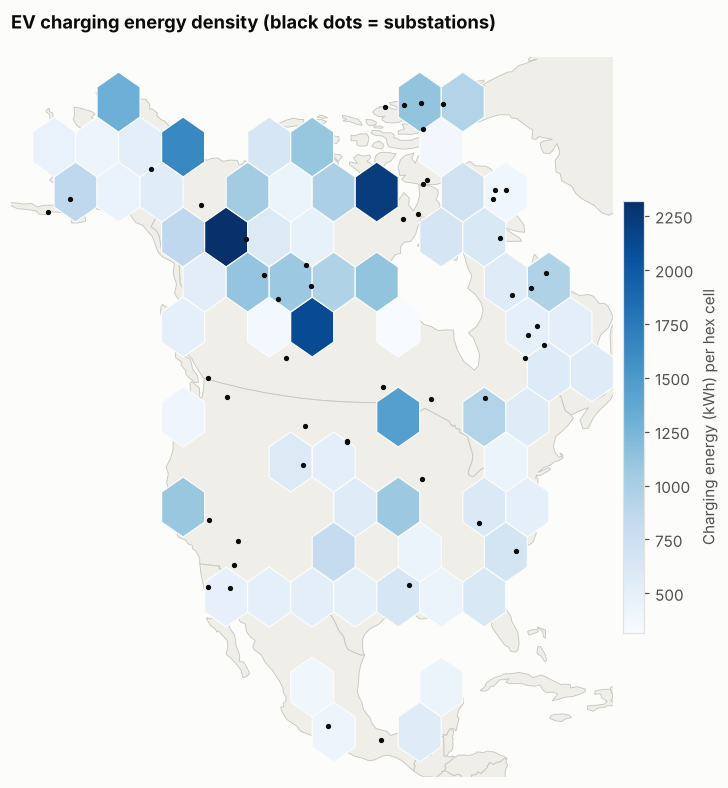

In [10]:
fig, ax = plt.subplots(figsize=(11, 8.5))
basemap(ax)
hb = ax.hexbin(st_gdf.geometry.x, st_gdf.geometry.y, C=st_gdf["electricity_consumption_kwh"], reduce_C_function=np.sum,
               gridsize=14, cmap="Blues", mincnt=1, edgecolors=SURFACE, linewidths=0.8, zorder=2,
               extent=ax.get_xlim() + ax.get_ylim())
cb = fig.colorbar(hb, ax=ax, shrink=0.6, pad=0.01)
cb.set_label("Charging energy (kWh) per hex cell")
sub_gdf.plot(ax=ax, color=INK, markersize=6, zorder=3)
ax.set_title("EV charging energy density (black dots = substations)")
save(fig, "07_05_demand_density"); plt.show()

## 8. The upgrade plan on the map

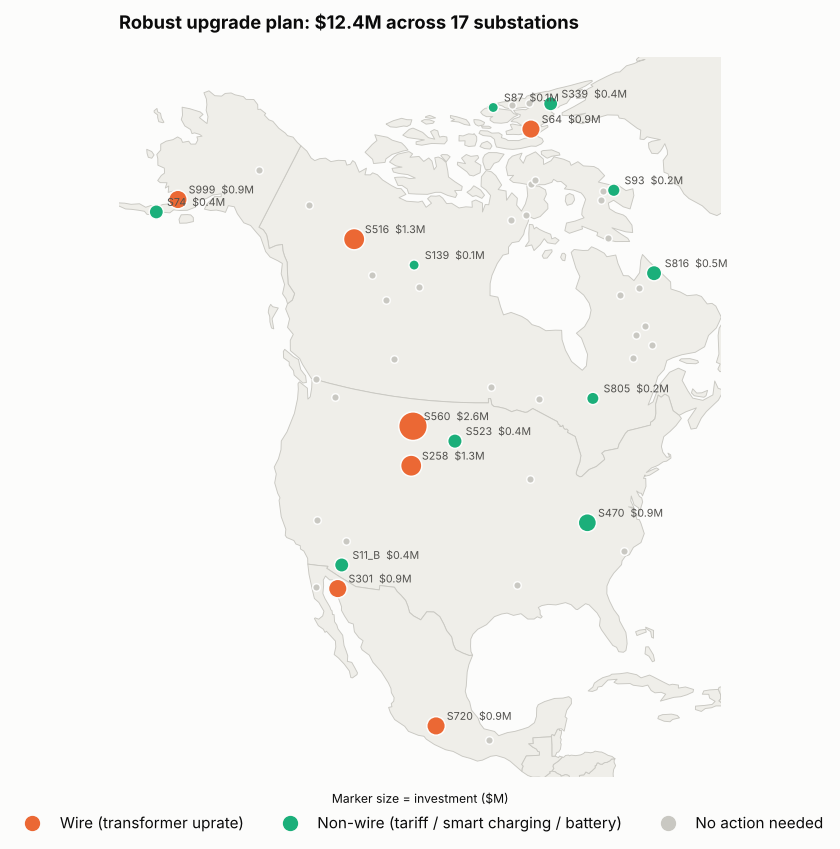

,substations,investment_musd
action_type,,
No action needed,33,0.00
Non-wire (tariff / smart charging / battery),10,3.56
Wire (transformer uprate),7,8.79


In [11]:
ACTION_COLORS = {"Wire (transformer uprate)": SERIES[1],
                 "Non-wire (tariff / smart charging / battery)": SERIES[2],
                 "No action needed": "#c9c8c2"}
fig, ax = plt.subplots(figsize=(11, 8.5))
basemap(ax)
for action, color in ACTION_COLORS.items():
    g = sub_gdf[sub_gdf["action_type"] == action]
    size = 25 if action == "No action needed" else 40 + g["cost ($M)"].fillna(0) * 120
    g.plot(ax=ax, color=color, markersize=size, edgecolor=SURFACE, linewidth=1, zorder=3 if action != "No action needed" else 2)
for sid, r in sub_gdf[sub_gdf["action_type"] != "No action needed"].iterrows():
    ax.annotate(f"{sid.replace('Substation_', 'S')}  ${r['cost ($M)']:.1f}M", (r.geometry.x, r.geometry.y),
                xytext=(7, 4), textcoords="offset points", fontsize=7, color=INK_2)
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markersize=9, color=c, label=l) for l, c in ACTION_COLORS.items()],
          loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, title="Marker size = investment ($M)", title_fontsize=8)
ax.set_title(f"Robust upgrade plan: ${sub_gdf['cost ($M)'].sum():.1f}M across {sub_gdf['cost ($M)'].notna().sum()} substations")
save(fig, "07_06_upgrade_plan_map"); plt.show()

sub_gdf.groupby("action_type").agg(substations=("capacity_mw", "size"), investment_musd=("cost ($M)", "sum"))

## 9. Export for BI tools
The enriched substation layer is saved as GeoJSON (in WGS84, which most tools expect), so it can be opened directly in Power BI, Tableau, QGIS, or kepler.gl.

In [12]:
export = sub_gdf.to_crs("EPSG:4326").reset_index()
export.to_file(PROCESSED / "substations_geo.geojson", driver="GeoJSON")
print(f"saved substations_geo.geojson with {len(export)} features and {export.shape[1] - 1} attributes")

saved substations_geo.geojson with 50 features and 13 attributes


## 10. Summary

| Question | Answer |
|---|---|
| Where are the bottlenecks? | Spread across the network. Tier 1 sites appear in several regions, not one hotspot (map 3). |
| Are they clustered? | No (permutation test, p ≈ 0.39). Bottlenecks are local problems, best solved substation by substation. |
| Does the station-substation mapping make sense? | No. 0 of 97 stations link to their nearest substation, and the median connection is ~2,700 km against ~365 km to the nearest. This is a critical data-quality issue for real deployment. |
| Does it change the plan? | Yes. A nearest-substation allocation gives 10 breaches instead of 9, but only 3 substations overlap. Connectivity validation must come before capex. |

**Next:** `08_executive_report.ipynb`: bring everything together into findings, recommendations, limitations, and a one-page executive summary.